In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dta
import numpy as np

In [2]:
path = 'data/RB9999.XSGE.csv'

df = pd.read_csv(path, parse_dates=['date'])

df.head()

,date,open,high,low,close,volume,money,open_interest,symbol
0,2009-03-27 09:01:00,3550.0,3662.0,3550.0,3660.0,10528.0,378617760.0,7910.0,RB0909
1,2009-03-27 09:02:00,3651.0,3661.0,3582.0,3582.0,6326.0,228733500.0,10226.0,RB0909
2,2009-03-27 09:03:00,3588.0,3632.0,3588.0,3609.0,4760.0,172252600.0,12144.0,RB0909
3,2009-03-27 09:04:00,3608.0,3626.0,3596.0,3602.0,5180.0,186904140.0,14376.0,RB0909
4,2009-03-27 09:05:00,3602.0,3604.0,3583.0,3600.0,5220.0,187556440.0,16558.0,RB0909


In [3]:
print(f'shape: {df.shape}\n')
print(f'dtypes: {df.dtypes}\n')
print(f'start_date: {df["date"].min()}, last_date: {df["date"].max()}')

shape: (924405, 9)

dtypes: date             datetime64[ns]
open                    float64
high                    float64
low                     float64
close                   float64
volume                  float64
money                   float64
open_interest           float64
symbol                   object
dtype: object

start_date: 2009-03-27 09:01:00, last_date: 2021-10-18 15:00:00


In [4]:
print(df.isna().sum())

date             0
open             0
high             0
low              0
close            0
volume           0
money            0
open_interest    0
symbol           0
dtype: int64


In [5]:
def check_dublicates(df):
    print(f'Dates are arranged in correct order: {df["date"].is_monotonic_increasing}')
    print(f'Dublicate count: {df.duplicated().sum()}')
    print(f'Date doublicate count: {df["date"].duplicated().sum()}')

check_dublicates(df)
print(f'Symbol unique: ', df['symbol'].unique())

Dates are arranged in correct order: False
Dublicate count: 118
Date doublicate count: 120
Symbol unique:  ['RB0909' 'RB0910' 'RB0911' 'RB0912' 'RB1001' 'RB1002' 'RB1005' 'RB1010'
 'RB1101' 'RB1105' 'RB1110' 'RB1201' 'RB1205' 'RB1210' 'RB1301' 'RB1305'
 'RB1310' 'RB1401' 'RB1405' 'RB1410' 'RB1501' 'RB1505' 'RB1510' 'RB1601'
 'RB1605' 'RB1610' 'RB1701' 'RB1705' 'RB1710' 'RB1801' 'RB1805' 'RB1810'
 'RB1901' 'RB1905' 'RB1910' 'RB2001' 'RB2005' 'RB2010' 'RB2101' 'RB2105'
 'RB2110' 'RB2201']


In [6]:
duplicate_by_date = df[df.duplicated(subset=['date'], keep=False)].sort_values('date')
print(duplicate_by_date)

                      date    open    high     low   close   volume  \
853140 2020-12-03 21:01:00  3868.0  3875.0  3868.0  3875.0  15730.0   
853260 2020-12-03 21:01:00  3868.0  3875.0  3868.0  3875.0  15730.0   
853141 2020-12-03 21:02:00  3875.0  3884.0  3875.0  3882.0  11179.0   
853261 2020-12-03 21:02:00  3875.0  3884.0  3875.0  3882.0  11179.0   
853142 2020-12-03 21:03:00  3882.0  3883.0  3877.0  3879.0   7677.0   
...                    ...     ...     ...     ...     ...      ...   
853257 2020-12-03 22:58:00  3884.0  3884.0  3882.0  3882.0    827.0   
853378 2020-12-03 22:59:00  3882.0  3883.0  3880.0  3880.0   1026.0   
853258 2020-12-03 22:59:00  3882.0  3883.0  3880.0  3880.0   1026.0   
853259 2020-12-03 23:00:00  3880.0  3883.0  3880.0  3881.0   1719.0   
853379 2020-12-03 23:00:00  3880.0  3883.0  3880.0  3881.0   1719.0   

              money  open_interest  symbol  
853140  608924940.0       678176.0  RB2101  
853260  608924940.0       678176.0  RB2101  
853141  4338

In [7]:
duplicate_by_ohlcv = df[df.duplicated(subset=[*df.columns], keep=False)].sort_values('date')
duplicate_by_day_but_not_by_ohlcv = pd.concat([duplicate_by_ohlcv, duplicate_by_date]).drop_duplicates(keep=False)
print(duplicate_by_day_but_not_by_ohlcv)

                      date    open    high     low   close  volume  \
853230 2020-12-03 22:31:00  3887.0  3892.0  3886.0  3889.0  8546.0   
853350 2020-12-03 22:31:00  3887.0  3892.0  3887.0  3889.0  8546.0   
853372 2020-12-03 22:53:00  3881.0  3883.0  3881.0  3882.0  1314.0   
853252 2020-12-03 22:53:00  3881.0  3883.0  3880.0  3882.0  1314.0   

              money  open_interest  symbol  
853230  332412720.0       654575.0  RB2101  
853350  332412720.0       654575.0  RB2101  
853372   51007490.0       651393.0  RB2101  
853252   51007490.0       651393.0  RB2101  


## First observation
A block of data from the night session on December 3, 2020, from 21:00 to 23:00 was found to contain duplicate entries. Most rows are identical, though two differ by one point in the "low" value. To ensure a unique timeline, I retain the first observation for each timestamp

In [8]:
df = df.drop_duplicates(subset=['date'], keep='first').sort_values('date')
check_dublicates(df)

Dates are arranged in correct order: True
Dublicate count: 0
Date doublicate count: 0


In [9]:
print('high>=open(close) :', (df['high'] >= df['open']).all() and (df['high'] >= df['close']).all())
print('low<=open(close) :', (df['low'] <= df['open']).all() and (df['low'] <= df['close']).all())
print('volume, money, open_interest > 0 : ', (df['volume'] >= 0).all() and (df['money'] >= 0).all() and (df['open_interest'] >= 0).all())

high>=open(close) : True
low<=open(close) : True
volume, money, open_interest > 0 :  True


In [10]:
one_day_start = dt.datetime(year=2019, day=12, month=4)
one_day_end = dt.datetime(year=2019, day=12, month=4, hour=23, minute=59, second=59)
one_day_df = df[(df['date'] >= one_day_start) & (df['date'] <= one_day_end)].sort_values('date')
one_day_df.head()

,date,open,high,low,close,volume,money,open_interest,symbol
723435,2019-04-12 09:01:00,3752.0,3757.0,3752.0,3755.0,24960.0,937108060.0,2267684.0,RB1910
723436,2019-04-12 09:02:00,3755.0,3755.0,3752.0,3754.0,12936.0,485608700.0,2266228.0,RB1910
723437,2019-04-12 09:03:00,3754.0,3755.0,3751.0,3755.0,18866.0,708043540.0,2263976.0,RB1910
723438,2019-04-12 09:04:00,3754.0,3758.0,3754.0,3755.0,18504.0,694891860.0,2261962.0,RB1910
723439,2019-04-12 09:05:00,3755.0,3755.0,3752.0,3753.0,10502.0,394175520.0,2262114.0,RB1910


In [11]:
print(f'shape: {one_day_df.shape}\n')
print(f'start_time: {one_day_df["date"].min()}, last_time: {one_day_df["date"].max()}\n')

one_day_date_copy = pd.DataFrame(index=one_day_df.index)
one_day_date_copy['date'] = one_day_df['date'].copy()
one_day_date_copy['prev_date'] = one_day_date_copy['date'].shift(1)

time_difference = one_day_date_copy['date'].diff()
result = one_day_date_copy[time_difference > pd.Timedelta('1min')][['prev_date', 'date']]

print('Intervals without orders', result)

shape: (345, 9)

start_time: 2019-04-12 09:01:00, last_time: 2019-04-12 23:00:00

Intervals without orders                  prev_date                date
723510 2019-04-12 10:15:00 2019-04-12 10:31:00
723570 2019-04-12 11:30:00 2019-04-12 13:31:00
723660 2019-04-12 15:00:00 2019-04-12 21:01:00


In [12]:
end_of_day_before_our = dt.datetime(year=2019, day=11, month=4, hour=23)
start_of_day_after_our = dt.datetime(year=2019, day=15, month=4, hour=9, minute=1)
print(df[df['date'] == end_of_day_before_our])
print(df[df['date'] == one_day_df["date"].min()])

print('\n')

print(df[df['date'] == one_day_df["date"].max()])
print(df[df['date'] == start_of_day_after_our])

                      date    open    high     low   close   volume  \
723434 2019-04-11 23:00:00  3755.0  3755.0  3751.0  3753.0  21018.0   

              money  open_interest  symbol  
723434  788806820.0      2262354.0  RB1910  
                      date    open    high     low   close   volume  \
723435 2019-04-12 09:01:00  3752.0  3757.0  3752.0  3755.0  24960.0   

              money  open_interest  symbol  
723435  937108060.0      2267684.0  RB1910  


                      date    open    high     low   close   volume  \
723779 2019-04-12 23:00:00  3823.0  3825.0  3821.0  3824.0  26846.0   

               money  open_interest  symbol  
723779  1.026424e+09      2307262.0  RB1910  
                      date    open    high     low   close   volume  \
723780 2019-04-15 09:01:00  3828.0  3831.0  3818.0  3827.0  72222.0   

               money  open_interest  symbol  
723780  2.762632e+09      2309914.0  RB1910  


## A remark about the Chinese exchange
The evening session of the previous workday adjoins the day session of the next trading day. Therefore, grouping solely by calendar date incorrectly splits the trading days

In [13]:
one_day_df['money/volume*close'] = one_day_df['money'] / one_day_df['close'] / one_day_df['volume']
print(one_day_df)

                      date    open    high     low   close   volume  \
723435 2019-04-12 09:01:00  3752.0  3757.0  3752.0  3755.0  24960.0   
723436 2019-04-12 09:02:00  3755.0  3755.0  3752.0  3754.0  12936.0   
723437 2019-04-12 09:03:00  3754.0  3755.0  3751.0  3755.0  18866.0   
723438 2019-04-12 09:04:00  3754.0  3758.0  3754.0  3755.0  18504.0   
723439 2019-04-12 09:05:00  3755.0  3755.0  3752.0  3753.0  10502.0   
...                    ...     ...     ...     ...     ...      ...   
723775 2019-04-12 22:56:00  3819.0  3821.0  3817.0  3819.0  12554.0   
723776 2019-04-12 22:57:00  3818.0  3823.0  3815.0  3821.0  13670.0   
723777 2019-04-12 22:58:00  3822.0  3824.0  3821.0  3823.0  11682.0   
723778 2019-04-12 22:59:00  3822.0  3824.0  3821.0  3822.0  12878.0   
723779 2019-04-12 23:00:00  3823.0  3825.0  3821.0  3824.0  26846.0   

               money  open_interest  symbol  money/volume*close  
723435  9.371081e+08      2267684.0  RB1910            9.998507  
723436  4.85608

Therefore, one RB contract for 10 tonnes

In [14]:
one_day_df['average_trade_price'] = one_day_df['money'] / 10 / one_day_df['volume']
print(one_day_df.head()['average_trade_price'], '\n')

print('low <= average <= high:', (one_day_df['average_trade_price'] >= one_day_df['low']).all() and (one_day_df['average_trade_price'] <= one_day_df['high']).all())

723435    3754.439343
723436    3753.932437
723437    3753.013569
723438    3755.360246
723439    3753.337650
Name: average_trade_price, dtype: float64 

low <= average <= high: True


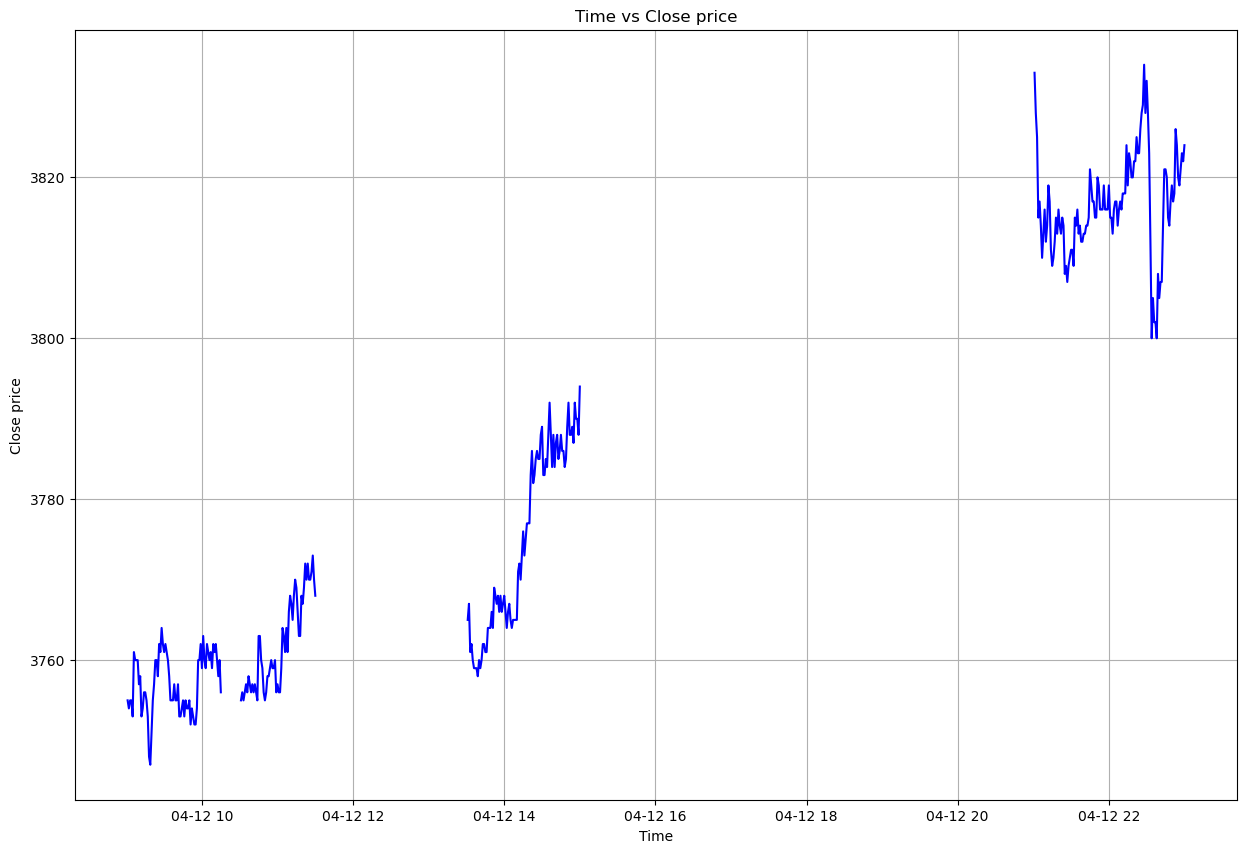

In [15]:
one_day_df = one_day_df.copy()

time_gap = one_day_df["date"].diff() > pd.Timedelta(minutes=1)
one_day_df["session_block"] = time_gap.cumsum()

fig, ax = plt.subplots(figsize=(15, 10))

for _, block in one_day_df.groupby("session_block"):
    ax.plot(block["date"], block["close"], color="blue")

ax.set_title("Time vs Close price")
ax.set_xlabel("Time")
ax.set_ylabel("Close price")
ax.grid(True)

plt.show()

In [16]:
trading_intervals = (
    one_day_df
    .groupby("session_block")
    .agg(
        start=("date", "min"),
        end=("date", "max"),
        number_bars=("date", "size"),
        max_high=("high", "max"),
        min_low=("low", "min"),
        open=('open', 'first'),
    )
)
trading_intervals['absolute_difference'] = trading_intervals['max_high'] - trading_intervals['min_low']
trading_intervals['percentage_difference'] = trading_intervals['absolute_difference'] / trading_intervals['open'] * 100
print(trading_intervals)


                            start                 end  number_bars  max_high  \
session_block                                                                  
0             2019-04-12 09:01:00 2019-04-12 10:15:00           75    3765.0   
1             2019-04-12 10:31:00 2019-04-12 11:30:00           60    3774.0   
2             2019-04-12 13:31:00 2019-04-12 15:00:00           90    3795.0   
3             2019-04-12 21:01:00 2019-04-12 23:00:00          120    3843.0   

               min_low    open  absolute_difference  percentage_difference  
session_block                                                               
0               3747.0  3752.0                 18.0               0.479744  
1               3753.0  3756.0                 21.0               0.559105  
2               3756.0  3768.0                 39.0               1.035032  
3               3796.0  3820.0                 47.0               1.230366  


In [17]:
one_day_df["return"] = (
    one_day_df
    .groupby("session_block")["close"]
    .pct_change()
)
std_returns = (
    one_day_df
    .groupby("session_block")["return"]
    .std()
)
print(std_returns)
print(one_day_df[['date', 'return']])

session_block
0    0.000644
1    0.000621
2    0.000671
3    0.000911
Name: return, dtype: float64
                      date    return
723435 2019-04-12 09:01:00       NaN
723436 2019-04-12 09:02:00 -0.000266
723437 2019-04-12 09:03:00  0.000266
723438 2019-04-12 09:04:00  0.000000
723439 2019-04-12 09:05:00 -0.000533
...                    ...       ...
723775 2019-04-12 22:56:00 -0.000262
723776 2019-04-12 22:57:00  0.000524
723777 2019-04-12 22:58:00  0.000523
723778 2019-04-12 22:59:00 -0.000262
723779 2019-04-12 23:00:00  0.000523

[345 rows x 2 columns]


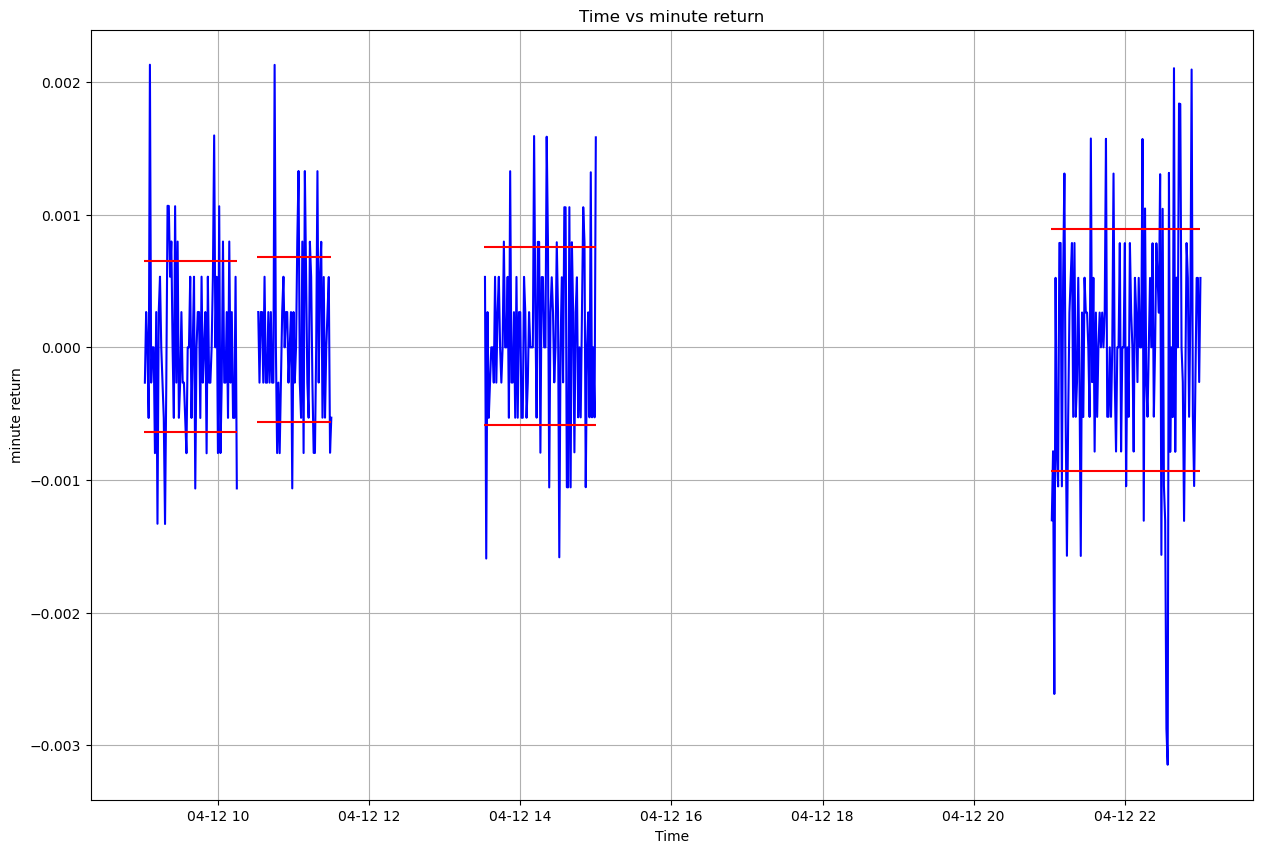

In [18]:
one_day_df = one_day_df.copy()

time_gap = one_day_df["date"].diff() > pd.Timedelta(minutes=1)
one_day_df["session_block"] = time_gap.cumsum()

fig, ax = plt.subplots(figsize=(15, 10))

for _, block in one_day_df.groupby("session_block"):
    ax.plot(block["date"], block["return"], color="blue")
    mean_return = block["return"].mean()
    std_return = block["return"].std()
    ax.hlines(
        mean_return + std_return,
        xmin=block["date"].min(),
        xmax=block["date"].max(),
        color="red"
    )

    ax.hlines(
        mean_return - std_return,
        xmin=block["date"].min(),
        xmax=block["date"].max(),
        color="red"
    )

ax.set_title("Time vs minute return")
ax.set_xlabel("Time")
ax.set_ylabel("minute return")
ax.grid(True)

plt.show()

## Observation second
On April 12, 2019, the RB evening session exhibited higher minute-by-minute volatility than the daytime blocks.

In [19]:
start_date = dt.datetime(day=1, month=4, year=2019)
end_date = dt.datetime(day=30,month=4, year=2019, hour=23, minute=59, second=59)
april_df = df[(df['date'] >= start_date) & (df['date'] <= end_date)]
print(april_df.shape)

(7005, 9)


In [20]:
rows_per_day = april_df.groupby(april_df["date"].dt.date).size()
print(rows_per_day)

date
2019-04-01    345
2019-04-02    345
2019-04-03    345
2019-04-04    225
2019-04-08    345
2019-04-09    345
2019-04-10    345
2019-04-11    345
2019-04-12    345
2019-04-15    345
2019-04-16    345
2019-04-17    345
2019-04-18    345
2019-04-19    345
2019-04-22    345
2019-04-23    345
2019-04-24    345
2019-04-25    345
2019-04-26    345
2019-04-29    345
2019-04-30    225
dtype: int64


In [21]:
target_date = pd.to_datetime("2019-04-04").date()

day_df = april_df[april_df["date"].dt.date == target_date]

print(day_df)

                      date    open    high     low   close   volume  \
721830 2019-04-04 09:01:00  3585.0  3586.0  3582.0  3585.0  14292.0   
721831 2019-04-04 09:02:00  3585.0  3585.0  3583.0  3583.0   7872.0   
721832 2019-04-04 09:03:00  3583.0  3585.0  3583.0  3584.0   5480.0   
721833 2019-04-04 09:04:00  3585.0  3585.0  3582.0  3582.0   5370.0   
721834 2019-04-04 09:05:00  3583.0  3585.0  3581.0  3581.0  11146.0   
...                    ...     ...     ...     ...     ...      ...   
722050 2019-04-04 14:56:00  3581.0  3584.0  3580.0  3583.0   7792.0   
722051 2019-04-04 14:57:00  3583.0  3587.0  3583.0  3587.0  10804.0   
722052 2019-04-04 14:58:00  3586.0  3590.0  3585.0  3589.0  26684.0   
722053 2019-04-04 14:59:00  3589.0  3591.0  3589.0  3590.0  24212.0   
722054 2019-04-04 15:00:00  3591.0  3595.0  3590.0  3594.0  31286.0   

               money  open_interest  symbol  
721830  5.122598e+08      1890446.0  RB1910  
721831  2.821415e+08      1893110.0  RB1910  
721832  1

## Observation three
In April 2019, a standard calendar day comprises 345 one-minute bars. April 4 and April 30 contain only 225 bars due to the absence of an evening session preceding public holidays.

In [22]:
april_df = april_df.copy()
time_gap = april_df["date"].diff() > pd.Timedelta(minutes=1)
april_df["session_block"] = time_gap.cumsum()

april_df["return"] = (
    april_df
    .groupby("session_block")["close"]
    .pct_change()
)

april_std = (
    april_df
    .groupby("session_block")["return"]
    .std()
)

print(april_df.head)
print(april_std.head())

<bound method NDFrame.head of                       date    open    high     low   close   volume  \
720795 2019-04-01 09:01:00  3759.0  3769.0  3759.0  3764.0  47356.0   
720796 2019-04-01 09:02:00  3764.0  3767.0  3760.0  3767.0  23368.0   
720797 2019-04-01 09:03:00  3767.0  3771.0  3766.0  3769.0  23192.0   
720798 2019-04-01 09:04:00  3769.0  3769.0  3765.0  3768.0   8468.0   
720799 2019-04-01 09:05:00  3767.0  3770.0  3765.0  3767.0   8726.0   
...                    ...     ...     ...     ...     ...      ...   
727795 2019-04-30 14:56:00  3823.0  3824.0  3822.0  3822.0  14818.0   
727796 2019-04-30 14:57:00  3822.0  3827.0  3822.0  3827.0  11486.0   
727797 2019-04-30 14:58:00  3826.0  3828.0  3825.0  3827.0  12208.0   
727798 2019-04-30 14:59:00  3827.0  3828.0  3826.0  3827.0  22912.0   
727799 2019-04-30 15:00:00  3828.0  3831.0  3827.0  3828.0  49040.0   

               money  open_interest  symbol  session_block    return  
720795  1.782696e+09      1431038.0  RB1905   

In [23]:
april_trading_intervals = (
    april_df
    .groupby("session_block")
    .agg(
        date=('date', 'min'),
        start_time=("date", "min"),
        end_time=("date", "max"),
        number_bars=("date", "size"),
    )
)

april_trading_intervals['minute_volatility'] = april_std
april_trading_intervals["start_time"] = april_trading_intervals["start_time"].dt.time
april_trading_intervals["end_time"] = april_trading_intervals["end_time"].dt.time
print(april_trading_intervals)

                             date start_time  end_time  number_bars  \
session_block                                                         
0             2019-04-01 09:01:00   09:01:00  10:15:00           75   
1             2019-04-01 10:31:00   10:31:00  11:30:00           60   
2             2019-04-01 13:31:00   13:31:00  15:00:00           90   
3             2019-04-01 21:01:00   21:01:00  23:00:00          120   
4             2019-04-02 09:01:00   09:01:00  10:15:00           75   
...                           ...        ...       ...          ...   
77            2019-04-29 13:31:00   13:31:00  15:00:00           90   
78            2019-04-29 21:01:00   21:01:00  23:00:00          120   
79            2019-04-30 09:01:00   09:01:00  10:15:00           75   
80            2019-04-30 10:31:00   10:31:00  11:30:00           60   
81            2019-04-30 13:31:00   13:31:00  15:00:00           90   

               minute_volatility  
session_block                     
0     

In [24]:
april_time_trading = (
    april_trading_intervals
    .groupby('start_time')
    .agg(
        count_blocks=('start_time', 'size'),
        mean_vol=('minute_volatility', 'mean'),
        median_vol=('minute_volatility', 'median'),
        max_vol=('minute_volatility', 'max'),
        min_vol=('minute_volatility', 'min')
    )
)
print(april_time_trading)

            count_blocks  mean_vol  median_vol   max_vol   min_vol
start_time                                                        
09:01:00              21  0.000630    0.000609  0.001223  0.000431
10:31:00              21  0.000557    0.000553  0.000801  0.000424
13:31:00              21  0.000638    0.000640  0.000901  0.000481
21:01:00              19  0.000604    0.000588  0.000944  0.000382


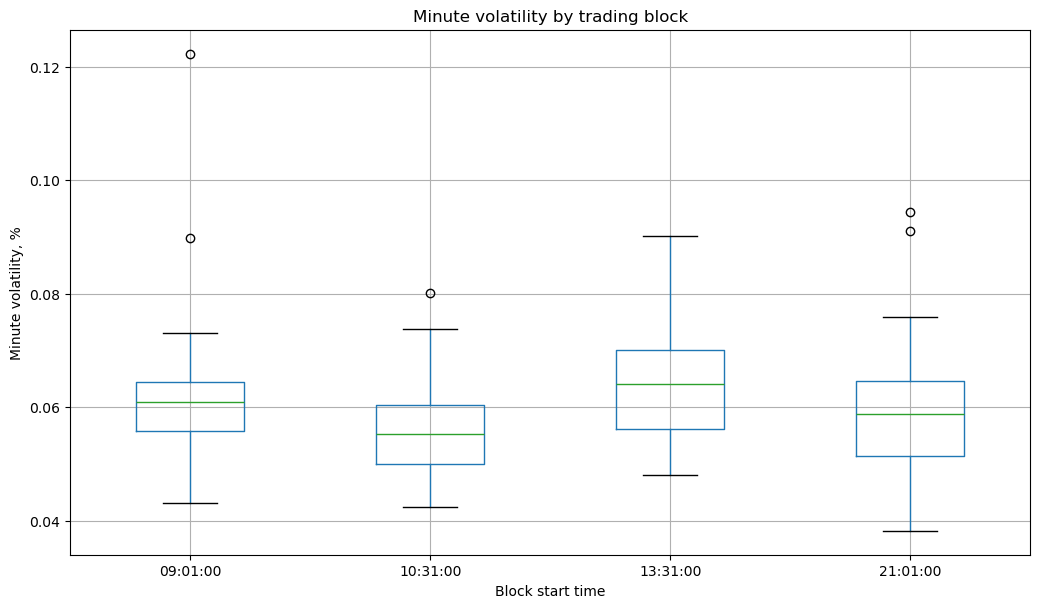

In [25]:
plot_df = april_trading_intervals.copy()
plot_df["minute_volatility_pct"] = (
    plot_df["minute_volatility"] * 100
)

ax = plot_df.boxplot(
    column="minute_volatility_pct",
    by="start_time",
    figsize=(12, 7),
    grid=True,
)

ax.set_title("Minute volatility by trading block")
ax.set_xlabel("Block start time")
ax.set_ylabel("Minute volatility, %")

plt.suptitle("")
plt.show()

In April 2019, the highest typical minute-by-minute volatility for RB was observed during the 13:31–15:00 interval, while the lowest occurred during the 10:31–11:30 interval. The distributions overlap significantly, with days of anomalously high volatility falling within certain intervals.

In [26]:
morning_blocks = april_trading_intervals[
    april_trading_intervals["start_time"].astype(str) == "09:01:00"
]

highest_morning_vol = morning_blocks.loc[
    morning_blocks["minute_volatility"].idxmax()
]

highest_morning_vol

date                 2019-04-08 09:01:00
start_time                      09:01:00
end_time                        10:15:00
number_bars                           75
minute_volatility               0.001223
Name: 15, dtype: object

In [27]:
start_date = highest_morning_vol['date']
end_date = dt.datetime(year=2019, month=4, day=8, hour=10, minute=15)
block = april_df[(april_df['date'] >= start_date) & (april_df['date'] <= end_date)]
block = block.copy()
block["previous_close"] = block["close"].shift(1)

max_return_index = block["return"].abs().idxmax()

block.loc[
    max_return_index,
    ["date", "previous_close", "close", "return"]
]

date              2019-04-08 09:02:00
previous_close                 3640.0
close                          3621.0
return                       -0.00522
Name: 722056, dtype: object

In [28]:
top5_indices = block["return"].abs().nlargest(5).index

top5 = block.loc[top5_indices]
print(top5)

                      date    open    high     low   close   volume  \
722056 2019-04-08 09:02:00  3639.0  3640.0  3619.0  3621.0  57534.0   
722072 2019-04-08 09:18:00  3637.0  3649.0  3637.0  3647.0  64186.0   
722088 2019-04-08 09:34:00  3659.0  3670.0  3658.0  3669.0  35140.0   
722119 2019-04-08 10:05:00  3701.0  3702.0  3689.0  3691.0  31498.0   
722074 2019-04-08 09:20:00  3654.0  3665.0  3654.0  3662.0  60126.0   

               money  open_interest  symbol  session_block    return  \
722056  2.086697e+09      1960370.0  RB1910             15 -0.005220   
722072  2.339079e+09      2006118.0  RB1910             15  0.002750   
722088  1.287957e+09      2021950.0  RB1910             15  0.002733   
722119  1.163454e+09      2045254.0  RB1910             15 -0.002702   
722074  2.200584e+09      2013616.0  RB1910             15  0.002189   

        previous_close  
722056          3640.0  
722072          3637.0  
722088          3659.0  
722119          3701.0  
722074         

In [29]:
original_volatility = block["return"].std()

returns_without_largest = block.loc[
    block.index != max_return_index,
    "return",
]

volatility_without_largest = returns_without_largest.std()

decrease_pct = (
    (original_volatility - volatility_without_largest)
    / original_volatility
    * 100
)

print("Initial volatility:", original_volatility)
print("Without largest volatility:", volatility_without_largest)
print("Decrease, %:", decrease_pct)

Initial volatility: 0.001223481414249867
Without largest volatility: 0.0010513271198982672
Decrease, %: 14.070854885617528


The most volatile morning block in April featured an anomalous one-minute drop of 0.522%. Excluding that minute reduced the volatility estimate by 14.1%, yet the remaining volatility stayed high. Consequently, the elevated volatility was driven by both the outlier and broader fluctuations within the block.

In [30]:
start_date = dt.datetime(day=1, month=1, year=2019)
end_date = dt.datetime(day=31,month=12, year=2019, hour=23, minute=59, second=59)
df_2019_year = df[(df['date'] >= start_date) & (df['date'] <= end_date)]
print(df_2019_year.shape)
print(df_2019_year.head())

(83340, 9)
                      date    open    high     low   close   volume  \
700905 2019-01-02 09:01:00  3398.0  3405.0  3389.0  3400.0  79572.0   
700906 2019-01-02 09:02:00  3401.0  3430.0  3401.0  3409.0  88858.0   
700907 2019-01-02 09:03:00  3410.0  3414.0  3409.0  3413.0  22584.0   
700908 2019-01-02 09:04:00  3412.0  3413.0  3403.0  3405.0  17688.0   
700909 2019-01-02 09:05:00  3404.0  3409.0  3404.0  3406.0  15522.0   

               money  open_interest  symbol  
700905  2.702739e+09      2399194.0  RB1905  
700906  3.039781e+09      2387102.0  RB1905  
700907  7.704125e+08      2388254.0  RB1905  
700908  6.029950e+08      2388366.0  RB1905  
700909  5.288321e+08      2389808.0  RB1905  


In [31]:
df_2019_year = df_2019_year.copy()
time_gap = df_2019_year["date"].diff() > pd.Timedelta(minutes=1)
df_2019_year["session_block"] = time_gap.cumsum()

df_2019_year["return"] = (
    df_2019_year
    .groupby("session_block")["close"]
    .pct_change()
)

df_2019_year_std = (
    df_2019_year
    .groupby("session_block")["return"]
    .std()
)

print(df_2019_year.head())

                      date    open    high     low   close   volume  \
700905 2019-01-02 09:01:00  3398.0  3405.0  3389.0  3400.0  79572.0   
700906 2019-01-02 09:02:00  3401.0  3430.0  3401.0  3409.0  88858.0   
700907 2019-01-02 09:03:00  3410.0  3414.0  3409.0  3413.0  22584.0   
700908 2019-01-02 09:04:00  3412.0  3413.0  3403.0  3405.0  17688.0   
700909 2019-01-02 09:05:00  3404.0  3409.0  3404.0  3406.0  15522.0   

               money  open_interest  symbol  session_block    return  
700905  2.702739e+09      2399194.0  RB1905              0       NaN  
700906  3.039781e+09      2387102.0  RB1905              0  0.002647  
700907  7.704125e+08      2388254.0  RB1905              0  0.001173  
700908  6.029950e+08      2388366.0  RB1905              0 -0.002344  
700909  5.288321e+08      2389808.0  RB1905              0  0.000294  


In [32]:
trading_intervals_2019_year = (
    df_2019_year
    .groupby("session_block")
    .agg(
        date=('date', 'min'),
        start_time=("date", "min"),
        end_time=("date", "max"),
        number_bars=("date", "size"),
    )
)

trading_intervals_2019_year['minute_volatility'] = df_2019_year_std
trading_intervals_2019_year["start_time"] = trading_intervals_2019_year["start_time"].dt.time
trading_intervals_2019_year["end_time"] = trading_intervals_2019_year["end_time"].dt.time
print(trading_intervals_2019_year)

                             date start_time  end_time  number_bars  \
session_block                                                         
0             2019-01-02 09:01:00   09:01:00  10:15:00           75   
1             2019-01-02 10:31:00   10:31:00  11:30:00           60   
2             2019-01-02 13:31:00   13:31:00  15:00:00           90   
3             2019-01-02 21:01:00   21:01:00  23:00:00          120   
4             2019-01-03 09:01:00   09:01:00  10:15:00           75   
...                           ...        ...       ...          ...   
964           2019-12-30 13:31:00   13:31:00  15:00:00           90   
965           2019-12-30 21:01:00   21:01:00  23:00:00          120   
966           2019-12-31 09:01:00   09:01:00  10:15:00           75   
967           2019-12-31 10:31:00   10:31:00  11:30:00           60   
968           2019-12-31 13:31:00   13:31:00  15:00:00           90   

               minute_volatility  
session_block                     
0     

In [33]:
trading_time_2019_year = (
    trading_intervals_2019_year
    .groupby('start_time')
    .agg(
        count_blocks=('start_time', 'size'),
        mean_vol=('minute_volatility', 'mean'),
        median_vol=('minute_volatility', 'median'),
        max_vol=('minute_volatility', 'max'),
        min_vol=('minute_volatility', 'min')
    )
)
print(trading_time_2019_year)

            count_blocks  mean_vol  median_vol   max_vol   min_vol
start_time                                                        
09:01:00             244  0.000642    0.000616  0.001356  0.000343
10:31:00             244  0.000583    0.000569  0.000986  0.000342
13:31:00             244  0.000650    0.000620  0.001301  0.000364
21:01:00             237  0.000591    0.000583  0.001043  0.000321


The results observed in April hold true for the entire year of 2019. RB’s minute-by-minute volatility varies according to the trading session: it is higher during the early morning and afternoon blocks and lower during the late morning block

In [34]:
trading_intervals_2019_year = (
    df_2019_year
    .groupby("session_block")
    .agg(
        date=('date', 'min'),
        start_time=("date", "min"),
        end_time=("date", "max"),
        number_bars=("date", "size"),
        mean_volume=('volume', 'mean'),
        open_interest_first_minute=('open_interest', 'first'),
        open_interest_last_minute=('open_interest', 'last'),
        unique_symbol_count = ('symbol', 'nunique')
    )
)
trading_intervals_2019_year['difference_OI'] = trading_intervals_2019_year['open_interest_last_minute'] - trading_intervals_2019_year['open_interest_first_minute']
trading_intervals_2019_year['difference_OI_percentage'] =  trading_intervals_2019_year['difference_OI'] / trading_intervals_2019_year['open_interest_first_minute'] * 100
trading_intervals_2019_year["start_time"] = trading_intervals_2019_year["start_time"].dt.time
trading_intervals_2019_year["end_time"] = trading_intervals_2019_year["end_time"].dt.time
trading_intervals_2019_year["OI_increased"] = (
    trading_intervals_2019_year["difference_OI"] > 0
)
print(trading_intervals_2019_year['unique_symbol_count'].max())
print(trading_intervals_2019_year)

1
                             date start_time  end_time  number_bars  \
session_block                                                         
0             2019-01-02 09:01:00   09:01:00  10:15:00           75   
1             2019-01-02 10:31:00   10:31:00  11:30:00           60   
2             2019-01-02 13:31:00   13:31:00  15:00:00           90   
3             2019-01-02 21:01:00   21:01:00  23:00:00          120   
4             2019-01-03 09:01:00   09:01:00  10:15:00           75   
...                           ...        ...       ...          ...   
964           2019-12-30 13:31:00   13:31:00  15:00:00           90   
965           2019-12-30 21:01:00   21:01:00  23:00:00          120   
966           2019-12-31 09:01:00   09:01:00  10:15:00           75   
967           2019-12-31 10:31:00   10:31:00  11:30:00           60   
968           2019-12-31 13:31:00   13:31:00  15:00:00           90   

                mean_volume  open_interest_first_minute  \
session_block  

In [35]:
trading_time_2019_year = (
    trading_intervals_2019_year
    .groupby('start_time')
    .agg(
        count_blocks=('start_time', 'size'),
        median_volume=('mean_volume', 'median'),
        median_diff_percentage_OI = ('difference_OI_percentage', 'median') 
    )
)
print(trading_time_2019_year)

            count_blocks  median_volume  median_diff_percentage_OI
start_time                                                        
09:01:00             244    8867.426667                   0.490552
10:31:00             244    6988.350000                   0.077665
13:31:00             244   10400.255556                  -0.958593
21:01:00             237    8434.583333                  -0.098937


## First hypothesis
Preliminary observation: blocks with higher median trading volume also tend to exhibit higher median minute volatility in 2019

In [36]:
oi_increase_by_time = (
    trading_intervals_2019_year
    .groupby("start_time")
    .agg(
        count_blocks=("OI_increased", "size"),
        share_OI_increased=("OI_increased", "mean"),
    )
)

oi_increase_by_time["share_OI_increased_pct"] = (
    oi_increase_by_time["share_OI_increased"] * 100
)

oi_increase_by_time

,count_blocks,share_OI_increased,share_OI_increased_pct
start_time,,,
09:01:00,244,0.672131,67.213115
10:31:00,244,0.540984,54.098361
13:31:00,244,0.266393,26.639344
21:01:00,237,0.468354,46.835443


In 2019, RB open interest exhibited an intraday pattern. It increased during 67.2% of early-morning blocks, with a median change of +0.49%, and decreased during 73.4% of afternoon blocks, with a median change of −0.96%. No comparably stable direction was observed during the late-morning or evening blocks

In [37]:
df_copy = df.copy()
df_copy['prev_symbol'] = df_copy['symbol'].shift(1)
df_copy['prev_close'] = df_copy['close'].shift(1)
df_copy['prev_date'] = df_copy['date'].shift(1)
df_copy['prev_open'] = df_copy['open'].shift(1)
df_copy['dif_time'] = df_copy['date'] - df_copy['prev_date']
df_copy['time'] = df_copy['date'].dt.time
df_copy['roll_gap_percentage'] = (df_copy['open'] / df_copy['prev_close'] - 1) * 100
df_diff_symbol = df_copy[(df_copy['prev_symbol'] != df_copy['symbol']) & (df_copy["prev_symbol"].notna())]
print(df_diff_symbol.shape)
print(df_diff_symbol.head())

(41, 16)
                     date    open    high     low   close   volume  \
16425 2009-07-14 09:01:00  3932.0  3932.0  3922.0  3922.0   3050.0   
20025 2009-08-05 09:01:00  4870.0  4870.0  4848.0  4867.0  25346.0   
24300 2009-09-01 09:01:00  4098.0  4113.0  4063.0  4066.0  40940.0   
29475 2009-10-12 09:01:00  3634.0  3644.0  3612.0  3617.0  69708.0   
33975 2009-11-09 09:01:00  4065.0  4074.0  4065.0  4068.0  71516.0   

              money  open_interest  symbol prev_symbol  prev_close  \
16425  1.197488e+08       230120.0  RB0910      RB0909      3886.0   
20025  1.231908e+09       299608.0  RB0911      RB0910      4848.0   
24300  1.671604e+09       483858.0  RB0912      RB0911      4133.0   
29475  2.532057e+09       510802.0  RB1001      RB0912      3644.0   
33975  2.910426e+09       789172.0  RB1002      RB1001      3890.0   

                prev_date  prev_open        dif_time      time  \
16425 2009-07-13 15:00:00     3887.0 0 days 18:01:00  09:01:00   
20025 2009-08-04 

In [38]:
roll_gap_statistic = df_diff_symbol.agg(
    min_roll_gap=("roll_gap_percentage", "min"),
    max_roll_gap=("roll_gap_percentage", "max"),
    median_roll_gap=("roll_gap_percentage", "median"),
    median_absolute_roll_gap=(
        "roll_gap_percentage",
        lambda x: x.abs().median(),
    ),
    positive_roll_gaps=(
        "roll_gap_percentage",
        lambda x: (x > 0).sum(),
    ),
    negative_roll_gaps=(
        "roll_gap_percentage",
        lambda x: (x < 0).sum(),
    ),
    zero_roll_gaps=(
        "roll_gap_percentage",
        lambda x: (x == 0).sum(),
    ),
)
roll_gap_statistic

,roll_gap_percentage
min_roll_gap,-9.395038
max_roll_gap,10.169492
median_roll_gap,-0.112423
median_absolute_roll_gap,2.240247
positive_roll_gaps,20.000000
negative_roll_gaps,21.000000
zero_roll_gaps,0.000000


The 41 contract transitions are directionally balanced, with 20 positive and 21 negative gaps. However, their median absolute size is 2.24%, with extremes near ±10%. Returns calculated directly across these transitions would therefore introduce substantial artificial volatility into the continuous series

In [39]:
df_change_time = df_diff_symbol.groupby('time').agg(count_change=('date', 'size'))
df_change_time

,count_change
time,
09:01:00,20
21:01:00,21


In [40]:
df_copy["is_roll"] = (
    (df_copy["prev_symbol"].notna())
    & (df_copy["symbol"].ne(df_copy["prev_symbol"]))
)
session_starts = df_copy[
    df_copy["time"].isin([
        dt.time(9, 1),
        dt.time(21, 1),
    ])
    & df_copy["prev_date"].notna()
].copy()

gap_comparison = (
    session_starts
    .groupby(["time", "is_roll"])
    .agg(
        count=("roll_gap_percentage", "size"),
        median_absolute_gap=(
            "roll_gap_percentage",
            lambda x: x.abs().median(),
        ),
    )
)

gap_comparison

count  median_absolute_gap
time     is_roll                            
09:01:00 False     3032             0.104836
         True        20             1.979387
21:01:00 False     1642             0.120749
         True        21             2.481390

Contract transitions produce much larger price discontinuities than ordinary session openings. The median absolute roll gap is 1.98% at 09:01 versus 0.10% for ordinary openings, and 2.48% at 21:01 versus 0.12%. Therefore, price changes across different symbols must not be treated as ordinary asset returns

In [41]:
df_copy["is_valid_1m_pair"] = (
    df_copy["prev_date"].notna()
    & (df_copy["date"] - df_copy["prev_date"]).eq(
        pd.Timedelta(minutes=1)
    )
    & df_copy["symbol"].eq(df_copy["prev_symbol"])
)
raw_return = (
    df_copy["close"] / df_copy["prev_close"] - 1
)

df_copy["clean_return_1m"] = raw_return.where(
    df_copy["is_valid_1m_pair"]
)
df_copy

,date,open,high,low,close,volume,money,open_interest,symbol,prev_symbol,prev_close,prev_date,prev_open,dif_time,time,roll_gap_percentage,is_roll,is_valid_1m_pair,clean_return_1m
0,2009-03-27 09:01:00,3550.0,3662.0,3550.0,3660.0,10528.0,378617760.0,7910.0,RB0909,None,NaN,NaT,NaN,NaT,09:01:00,NaN,False,False,NaN
1,2009-03-27 09:02:00,3651.0,3661.0,3582.0,3582.0,6326.0,228733500.0,10226.0,RB0909,RB0909,3660.0,2009-03-27 09:01:00,3550.0,0 days 00:01:00,09:02:00,-0.245902,False,True,-0.021311
2,2009-03-27 09:03:00,3588.0,3632.0,3588.0,3609.0,4760.0,172252600.0,12144.0,RB0909,RB0909,3582.0,2009-03-27 09:02:00,3651.0,0 days 00:01:00,09:03:00,0.167504,False,True,0.007538
3,2009-03-27 09:04:00,3608.0,3626.0,3596.0,3602.0,5180.0,186904140.0,14376.0,RB0909,RB0909,3609.0,2009-03-27 09:03:00,3588.0,0 days 00:01:00,09:04:00,-0.027709,False,True,-0.001940
4,2009-03-27 09:05:00,3602.0,3604.0,3583.0,3600.0,5220.0,187556440.0,16558.0,RB0909,RB0909,3602.0,2009-03-27 09:04:00,3608.0,0 days 00:01:00,09:05:00,0.000000,False,True,-0.000555
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
924400,2021-10-18 14:56:00,5435.0,5443.0,5434.0,5439.0,4841.0,263334090.0,1172137.0,RB2201,RB2201,5435.0,2021-10-18 14:55:00,5432.0,0 days 00:01:00,14:56:00,0.000000,False,True,0.000736
924401,2021-10-18 14:57:00,5439.0,5447.0,5438.0,5443.0,4892.0,266289340.0,1172273.0,RB2201,RB2201,5439.0,2021-10-18 14:56:00,5435.0,0 days 00:01:00,14:57:00,0.000000,False,True,0.000735
924402,2021-10-18 14:58:00,5443.0,5446.0,5440.0,5440.0,3995.0,217436130.0,1171340.0,RB2201,RB2201,5443.0,2021-10-18 14:57:00,5439.0,0 days 00:01:00,14:58:00,0.000000,False,True,-0.000551
924403,2021-10-18 14:59:00,5441.0,5441.0,5428.0,5429.0,8119.0,440961410.0,1169680.0,RB2201,RB2201,5440.0,2021-10-18 14:58:00,5443.0,0 days 00:01:00,14:59:00,0.018382,False,True,-0.002022
